# Build Analytical Curves

In [28]:
# =====================================================================
# CELL 1 -- build the analytic curves ONCE and cache them to disk.
#
# Run this after changing XI_GRID or WTB_LIST; otherwise it loads the
# cache in a few milliseconds and does nothing.  The integration is the
# slow part (a few seconds per frequency), so it must not sit in the
# plotting cell.
#
# Two theories are stored:
#   g_mrsh   full MRSh, Bacri Eq. (6), integrated as a vector ODE for xi_e.
#            This is the model compute_M actually solves.
#   g_bacri  Bacri Eqs. (7)-(8), the O(Omega tau_B) reduction printed in
#            their Fig. 3.  Integrated correctly the two agree to ~1e-5;
#            keeping both is a free consistency check.
#
# Two things are load-bearing and were wrong in the old version:
#   * the averaging window is a WHOLE number of field periods.  A window
#     of "12 tau_B" leaves a partial period whose contribution does not
#     cancel and shifts g by several per cent.
#   * the RK4 step is capped by the STIFFEST RATE, not by the period.
#     The parallel relaxation is L/(L' tau_B) -> xi_e^2/tau_B, so
#     h*xi_0^2 must stay well under the RK4 limit of 2.785.  The old code
#     used 200 steps per period, giving h*xi_0^2 = 6.3 at xi_0 = 20 --
#     unstable, and it inflated |g| by 15%.
# =====================================================================

import os
import numpy as np

CACHE   = "theory_cache.npz"
XI_GRID = np.linspace(0.0, 20.0, 81)          # 0.25 spacing
XI_EXTRA = [1.0, 2.5, 5.0, 10.0, 15.0, 20.0]  # sweep values, merged in exactly
WTB_LIST = [0.0, 0.1, 0.5, 1.0, 1.5, 2.0]

OM_TAUB    = 1e-3   # Omega*tau_B for the theory.  g is independent of it
                    # (verified: identical to 5 dp over 1e-5 .. 1e-2).
SETTLE_PER = 8      # periods discarded
AVG_PER    = 6      # periods averaged -- WHOLE periods
H_TARGET   = 1e-3   # max RK4 step, in tau_B
SAFE_FAC   = 0.5    # cap on h*xi_0^2 (RK4 stable to 2.785)


def L_vec(x):
    """coth(x) - 1/x.  Series below 0.2 avoids the coth - 1/x cancellation;
    asymptote above 200 avoids sinh overflow.  L is ODD -- xi_e crosses zero
    every field reversal, so the sign is load-bearing."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = a * (1/3 + a**2 * (-1/45 + a**2 * (2/945 - a**2/4725)))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0 - 1.0/s, 1.0/np.tanh(sc) - 1.0/s)
    return np.sign(x) * np.where(a < 0.2, ser, ex)


def dL_vec(x):
    """L'(x) = 1/x^2 - 1/sinh^2(x).  EVEN."""
    a = np.abs(np.asarray(x, float))
    s = np.where(a < 1e-12, 1.0, a)
    ser = 1/3 + a**2 * (-1/15 + a**2 * (2/189 - a**2/675))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0/s**2, 1.0/s**2 - 1.0/np.sinh(sc)**2)
    return np.where(a < 0.2, ser, ex)


def B_vec(x):
    """B(x) = 3/(2x) - 1/(2L(x)).  ODD."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = -a/10.0 + a**3/350.0 - a**5/3500.0
    return np.sign(x) * np.where(a < 0.05, ser, 1.5/s - 0.5/L_vec(s))


def _static(xi0):
    """Closed form at omega = 0:  g = xi_0 L^2 / (xi_0 - L)."""
    l = L_vec(xi0); out = np.zeros_like(xi0); nz = xi0 > 1e-10
    out[nz] = xi0[nz] * l[nz]**2 / (xi0[nz] - l[nz])
    return out


def _step(xi0, wtB):
    P = 2.0 * np.pi / wtB
    rate = max(1.0, float(np.max(xi0)**2))
    h = min(H_TARGET, SAFE_FAC / rate, P / 400.0)
    N = int(np.ceil(P / h))
    return P, N, P / N                      # exact whole-period tiling


def g_mrsh(xi0, wtB):
    """Full MRSh Eq. (6), vector ODE for xi_e, vectorised over xi0."""
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)
    P, N, h = _step(xi0, wtB)
    ax = xi0.copy(); ay = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0

    def f(t, ax, ay):
        xt = xi0 * np.cos(wtB * t)
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        nx, ny = ax/s, ay/s
        Le, dLe = L_vec(s), dL_vec(s)
        xpar = nx * xt
        par = -(Le/dLe) * (1.0 - xpar/s)
        cp  = 0.5 * (s/Le - 1.0)
        return (-OM_TAUB*ay + par*nx + cp*(xt - nx*xpar),
                 OM_TAUB*ax + par*ny + cp*(   - ny*xpar))

    def obs(t, ax, ay):
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        return L_vec(s) * ay/s * np.cos(wtB*t)

    for phase in (0, 1):
        for _ in range(N * (SETTLE_PER if phase == 0 else AVG_PER)):
            if phase:
                a0 = obs(t, ax, ay)
            k1 = f(t,     ax,           ay)
            k2 = f(t+h/2, ax+h/2*k1[0], ay+h/2*k1[1])
            k3 = f(t+h/2, ax+h/2*k2[0], ay+h/2*k2[1])
            k4 = f(t+h,   ax+h*k3[0],   ay+h*k3[1])
            ax = ax + h/6*(k1[0]+2*k2[0]+2*k3[0]+k4[0])
            ay = ay + h/6*(k1[1]+2*k2[1]+2*k3[1]+k4[1])
            t += h
            if phase:
                I = I + 0.5*h*(a0 + obs(t, ax, ay))
    return xi0 * I / (AVG_PER * P) / (2.0 * OM_TAUB)


def g_bacri(xi0, wtB):
    """Bacri Eqs. (7)-(8) with Y = F L(xi_e), which removes the 1/xi_e
    singularity analytically."""
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)
    P, N, h = _step(xi0, wtB)
    xe = xi0.copy(); Y = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0

    def fx(t, xe):
        Lv, dLv = L_vec(xe), dL_vec(xe)
        s = np.where(np.abs(xe) < 1e-12, 1.0, xe)
        return -Lv/dLv + (Lv/(s*dLv)) * xi0 * np.cos(wtB*t)

    def fy(t, xe, Y):
        return L_vec(xe) - Y*(1.0 - xi0*np.cos(wtB*t)*B_vec(xe))

    for phase in (0, 1):
        for _ in range(N * (SETTLE_PER if phase == 0 else AVG_PER)):
            if phase:
                a0 = Y * np.cos(wtB*t)
            k1x = fx(t, xe);                        k1y = fy(t, xe, Y)
            k2x = fx(t+h/2, xe+h/2*k1x)
            k2y = fy(t+h/2, xe+h/2*k1x, Y+h/2*k1y)
            k3x = fx(t+h/2, xe+h/2*k2x)
            k3y = fy(t+h/2, xe+h/2*k2x, Y+h/2*k2y)
            k4x = fx(t+h,   xe+h*k3x)
            k4y = fy(t+h,   xe+h*k3x, Y+h*k3y)
            xe = xe + h/6*(k1x + 2*k2x + 2*k3x + k4x)
            Y  = Y  + h/6*(k1y + 2*k2y + 2*k3y + k4y)
            t += h
            if phase:
                I = I + 0.5*h*(a0 + Y*np.cos(wtB*t))
    return 0.5 * xi0 * I / (AVG_PER * P)


def build_cache(path=CACHE, force=False):
    grid = np.unique(np.concatenate([XI_GRID, np.asarray(XI_EXTRA, float)]))
    wtbs = np.asarray(WTB_LIST, float)
    if os.path.exists(path) and not force:
        d = np.load(path)
        if (d["grid"].shape == grid.shape and np.allclose(d["grid"], grid)
                and d["wtbs"].shape == wtbs.shape and np.allclose(d["wtbs"], wtbs)):
            print(f"cache hit: {path}  ({len(grid)} xi0 x {len(wtbs)} wtB)")
            return dict(d)
        print("cache stale (grid or wtB list changed) -- rebuilding")

    import time
    out = {"grid": grid, "wtbs": wtbs}
    for w in wtbs:
        t0 = time.time()
        out[f"mrsh_{w:g}"]  = g_mrsh(grid, w)
        out[f"bacri_{w:g}"] = g_bacri(grid, w)
        d = np.abs(out[f"mrsh_{w:g}"] - out[f"bacri_{w:g}"]).max()
        print(f"  wtB = {w:<5g}  {time.time()-t0:5.1f} s   "
              f"max|Eq.(6) - Eqs.(7)-(8)| = {d:.2e}")
    np.savez(path, **out)
    print(f"wrote {path}")
    return out


THEORY = build_cache()
print("\nTHEORY['grid'], THEORY['mrsh_<w>'], THEORY['bacri_<w>'] are ready.")

cache hit: theory_cache.npz  (81 xi0 x 6 wtB)

THEORY['grid'], THEORY['mrsh_<w>'], THEORY['bacri_<w>'] are ready.


# Curve Analysis

38 run(s) in output_poiseuille_experiment_alt/   [column: ux]
nY = 50   S = 20837.5000   t_visc = 10005 steps (run = 20.0 t_visc)
eta from DC of the last 40% of snapshots (1-9 per run)
eta_0 = 0.05000005  (xi0=0 run, nominal 0.050000, +0.000%)

 xi0  wtB   iter          eta           g  g_mrsh         dev         ratio    swing  fit_res    resid
 0.0  0.0 200000   0.05000005     +0.0000 +0.0000     +0.0000           NaN 6.15e-06 0.00e+00 7.78e-17
 1.0  0.0 200000   0.05213812     +0.1425 +0.1426     -0.0001         0.999 3.60e-06 0.00e+00 7.43e-06
 2.5  0.0 200000   0.05747827     +0.4985 +0.4989     -0.0004         0.999 9.62e-07 0.00e+00 2.34e-05
 5.0  0.0 200000   0.06142321     +0.7615 +0.7621     -0.0006         0.999 3.90e-07 0.00e+00 3.33e-05
10.0  0.0 200000   0.06334210     +0.8895 +0.8901     -0.0006         0.999 2.74e-07 0.00e+00 3.76e-05
15.0  0.0 200000   0.06392369     +0.9282 +0.9289     -0.0007         0.999 2.21e-07 0.00e+00 3.89e-05
20.0  0.0 200000   0.06420244     

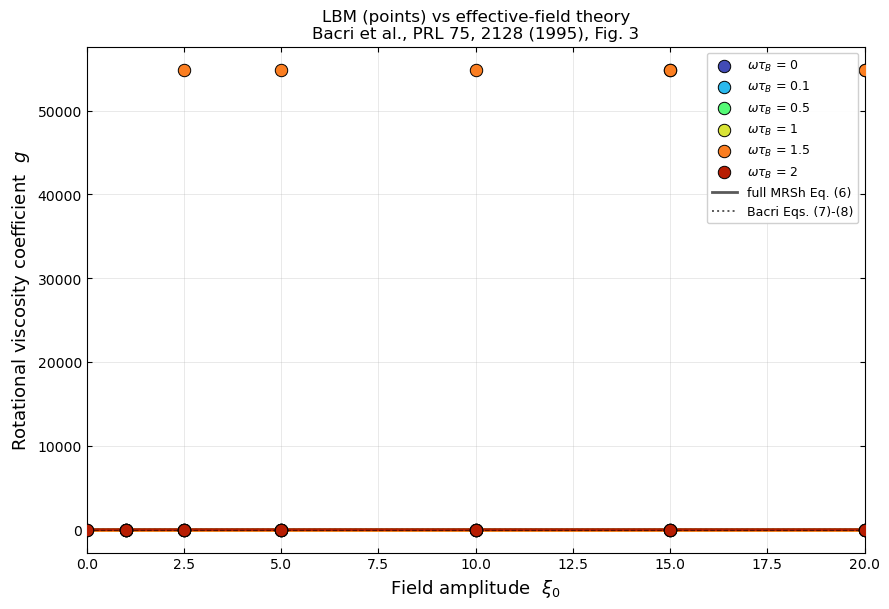

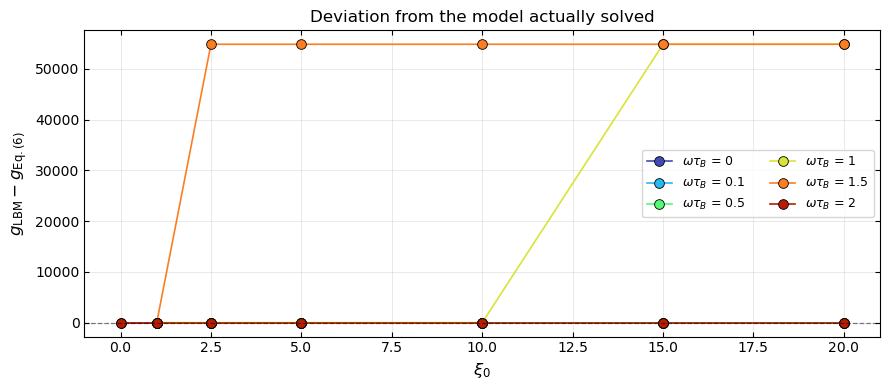

In [24]:
# =====================================================================
# CELL 2 -- read the runs, extract g, overlay on the cached curves.
#
# Requires CELL 1 to have run (THEORY in scope, or theory_cache.npz on disk).
#
#     eta = rho * S * F / (2 Q),   Q = sum_j rho_j ux_j
#     S   = sum_j (j + 1/2)(nY - 1/2 - j)          [exact discrete sum]
#     g   = (2 / (3 phi_p)) (eta - eta_0) / eta_0  [Bacri Eq. (10)]
#
# eta is taken from the DC part of a harmonic fit over the CONVERGED TAIL,
# not from one snapshot.  Under an alternating field the flow settles on a
# limit cycle -- the torque carries a 2*omega component -- so a snapshot
# samples one phase of it.  Snapshot spacing rarely divides the 2w period,
# so a tail MEAN does not cancel the ripple either; the fit does not need
# commensurate sampling.  If the ripple is small (2 w t_visc >> 1) the fit
# and the last snapshot agree, and that agreement is itself the check.
# =====================================================================

import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- must match the C++ globals -------------------------------------
BASE_DIR = "output_poiseuille_experiment_alt"
phi_p  = 0.2          # PARTICLE volume fraction (the theory's phi)
eta_h  = 0.05         # field-free dynamic viscosity
rho_h  = 1.975        # heavy-phase density
tau_B  = 20.0         # Brownian time in lattice steps
UX_COL = "ux"         # "ux_avg" if the C++ writes a period average
TAIL   = 0.40         # fraction of snapshots treated as converged
NEDGE  = 1            # wall rows dropped in the shape diagnostic only

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

if "THEORY" not in globals():
    THEORY = dict(np.load("theory_cache.npz"))


def all_csvs(folder):
    out = []
    for p in glob.glob(os.path.join(folder, "output_t_*.csv")):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        if m:
            out.append((int(m.group(1)), p))
    return sorted(out)


def read_run(path, S, ux_col=UX_COL):
    df = pd.read_csv(path, skipinitialspace=True)
    col = ux_col if ux_col in df.columns else "ux"
    prof = df.groupby("j").agg(ux=(col, "mean"), rho=("rho", "mean")).sort_index()
    y, ux, rho = (prof.index.to_numpy(float), prof["ux"].to_numpy(),
                  prof["rho"].to_numpy())
    F, Q = float(df["Fb_x"].mean()), float(np.sum(rho*ux))
    eta = float(rho.mean()) * S * F / (2.0*Q) if abs(Q) > 1e-30 else np.nan
    return eta, y, ux, col


def parabola_residual(y, ux, nY):
    yi, ui = y[NEDGE:len(y)-NEDGE], ux[NEDGE:len(ux)-NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis*ui) / np.sum(basis*basis))
    return float(np.sqrt(np.mean((ui - amp*basis)**2)) /
                 max(float(np.max(np.abs(ui))), 1e-300))


def dc_from_run(folder, wtB, S, nY):
    """eta from the DC part of the converged tail; also swing and fit residual."""
    recs = all_csvs(folder)
    if not recs:
        return None
    it_all = np.array([r[0] for r in recs], float)
    cut = it_all.min() + (1.0 - TAIL)*(it_all.max() - it_all.min())
    keep = [(i, p) for i, p in recs if i >= cut] or recs[-2:]

    it, eta = [], []
    for i, p in keep:
        e, y, ux, col = read_run(p, S)
        if np.isfinite(e):
            it.append(float(i)); eta.append(e)
    if not it:
        return None
    it, eta = np.asarray(it), np.asarray(eta)

    if wtB > 1e-12 and len(eta) >= 6:
        th = 2.0*np.pi*it / (np.pi*tau_B/wtB)           # 2*omega phase
        M = np.column_stack([np.ones_like(th), np.cos(th), np.sin(th),
                             np.cos(2*th), np.sin(2*th)])
        c, *_ = np.linalg.lstsq(M, eta, rcond=None)
        eta_dc = float(c[0])
        fit_res = float(np.sqrt(np.mean((eta - M @ c)**2)) / max(abs(eta_dc), 1e-300))
    else:
        eta_dc, fit_res = float(eta.mean()), 0.0

    swing = float(eta.max() - eta.min()) / max(abs(eta_dc), 1e-300)
    _, y, ux, col = read_run(keep[-1][1], S)
    return eta_dc, swing, fit_res, y, ux, int(it[-1]), len(it), col


# ---- learn nY from the data, then read every run ---------------------
folders = [(f, FOLDER_RE.match(f)) for f in sorted(os.listdir(BASE_DIR))]
folders = [(f, m) for f, m in folders
           if m and os.path.isdir(os.path.join(BASE_DIR, f))]
if not folders:
    raise SystemExit(f"No run folders under {BASE_DIR}/")

probe = all_csvs(os.path.join(BASE_DIR, folders[0][0]))[-1][1]
nY = pd.read_csv(probe, skipinitialspace=True)["j"].nunique()
_j = np.arange(nY)
S = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))
t_visc = rho_h * nY**2 / (np.pi**2 * eta_h)

rows, used_col = [], None
for name, m in folders:
    xi0, wtB = float(m.group(1)), float(m.group(2))
    got = dc_from_run(os.path.join(BASE_DIR, name), wtB, S, nY)
    if got is None:
        print(f"  skip {name}: no usable CSV");  continue
    eta, swing, fit_res, y, ux, it, ntail, used_col = got
    if len(y) != nY:
        print(f"  skip {name}: nY={len(y)} != {nY}");  continue
    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, ntail=ntail, eta=eta,
                     swing=swing, fit_res=fit_res,
                     resid=parabola_residual(y, ux, nY), y=y, ux=ux))

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)
print(f"{len(res)} run(s) in {BASE_DIR}/   [column: {used_col}]")
print(f"nY = {nY}   S = {S:.4f}   t_visc = {t_visc:.0f} steps "
      f"(run = {res.iter.max()/t_visc:.1f} t_visc)")
print(f"eta from DC of the last {TAIL:.0%} of snapshots "
      f"({res.ntail.min()}-{res.ntail.max()} per run)")

zero = res[np.isclose(res.xi0, 0.0)]
eta0 = float(zero.eta.mean()) if len(zero) else eta_h
src = "xi0=0 run" if len(zero) else "eta_h fallback"
print(f"eta_0 = {eta0:.8f}  ({src}, nominal {eta_h:.6f}, "
      f"{100*(eta0/eta_h-1):+.3f}%)\n")
if abs(eta0/eta_h - 1) > 0.02:
    print("  WARNING: eta_0 >2% off nominal -- zero-field run not converged.\n")

res["g"] = (2.0/(3.0*phi_p)) * (res.eta - eta0) / eta0

# ---- theory at the data points, straight from the cache -------------
grid = THEORY["grid"]
res["g_mrsh"]  = [np.interp(x, grid, THEORY[f"mrsh_{w:g}"])  for x, w in zip(res.xi0, res.wtB)]
res["g_bacri"] = [np.interp(x, grid, THEORY[f"bacri_{w:g}"]) for x, w in zip(res.xi0, res.wtB)]
res["dev"]   = res.g - res.g_mrsh
res["ratio"] = np.where(np.abs(res.g_mrsh) > 1e-12, res.g/res.g_mrsh, np.nan)

with pd.option_context("display.width", 220, "display.max_columns", 20):
    print(res[["xi0","wtB","iter","eta","g","g_mrsh","dev","ratio",
               "swing","fit_res","resid"]]
          .to_string(index=False,
                     formatters={"eta":"{:.8f}".format, "g":"{:+.4f}".format,
                                 "g_mrsh":"{:+.4f}".format, "dev":"{:+.4f}".format,
                                 "ratio":"{:.3f}".format, "swing":"{:.2e}".format,
                                 "fit_res":"{:.2e}".format, "resid":"{:.2e}".format}))

print(f"\nvs full MRSh Eq.(6):  max |dev| = {res.dev.abs().max():.4f}"
      f"   RMS {np.sqrt((res.dev**2).mean()):.4f}")
for w in sorted(res.wtB.unique()):
    s = res[res.wtB == w]
    print(f"   omega*tau_B = {w:<5g} max |dev| = {s.dev.abs().max():.4f}")
for _, r in res[res.fit_res > 5e-3].iterrows():
    print(f"   WARNING xi0={r.xi0:g}, wtB={r.wtB:g}: fit_res={r.fit_res:.1e} "
          f"-- tail too short for a clean DC extraction")

# ---- plot ------------------------------------------------------------
wtBs = sorted(res.wtB.unique())
colors = plt.cm.turbo(np.linspace(0.08, 0.92, max(1, len(wtBs))))
fig, ax = plt.subplots(figsize=(9, 6.2))
for c, w in zip(colors, wtBs):
    ax.plot(grid, THEORY[f"mrsh_{w:g}"],  color=c, lw=2.0, ls="-", zorder=2)
    ax.plot(grid, THEORY[f"bacri_{w:g}"], color=c, lw=1.4, ls=":", zorder=2, alpha=0.75)
    sub = res[res.wtB == w].sort_values("xi0")
    ax.scatter(sub.xi0, sub.g, s=80, color=c, edgecolors="k", linewidths=0.7,
               zorder=3, label=rf"$\omega\tau_B$ = {w:g}")
ax.plot([], [], color="0.35", lw=2.0, ls="-", label="full MRSh Eq. (6)")
ax.plot([], [], color="0.35", lw=1.4, ls=":", label="Bacri Eqs. (7)-(8)")
ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlim(0, grid.max())
ax.set_xlabel(r"Field amplitude  $\xi_0$", fontsize=13)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=13)
ax.set_title("LBM (points) vs effective-field theory\n"
             "Bacri et al., PRL 75, 2128 (1995), Fig. 3", fontsize=12)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, loc="best", framealpha=0.92)
fig.tight_layout()
plt.savefig("bacri_fig3_lbm.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.0))
for c, w in zip(colors, wtBs):
    sub = res[res.wtB == w].sort_values("xi0")
    ax.plot(sub.xi0, sub.dev, "o-", color=c, ms=7, lw=1.2,
            markeredgecolor="k", markeredgewidth=0.6,
            label=rf"$\omega\tau_B$ = {w:g}")
ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlabel(r"$\xi_0$", fontsize=12)
ax.set_ylabel(r"$g_{\rm LBM} - g_{\rm Eq.(6)}$", fontsize=12)
ax.set_title("Deviation from the model actually solved", fontsize=12)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
plt.savefig("bacri_fig3_residual.png", dpi=150)
plt.show()

In [25]:
# =====================================================================
# CELL 1 -- build the analytic curves ONCE and cache them to disk.
#
# Run this after changing XI_GRID or WTB_LIST; otherwise it loads the
# cache in a few milliseconds and does nothing.  The integration is the
# slow part (a few seconds per frequency), so it must not sit in the
# plotting cell.
#
# Two theories are stored:
#   g_mrsh   full MRSh, Bacri Eq. (6), integrated as a vector ODE for xi_e.
#            This is the model compute_M actually solves.
#   g_bacri  Bacri Eqs. (7)-(8), the O(Omega tau_B) reduction printed in
#            their Fig. 3.  Integrated correctly the two agree to ~1e-5;
#            keeping both is a free consistency check.
#   g_demag  Eq. (6) WITH the transverse demagnetising field.  In a 2D slab
#            with x-uniform M, B_y = -dA_z/dx = 0 identically, so
#                H_y = B_y/mu0 - M_y = -M_y     (demagnetising factor N = 1).
#            That is an identity of the geometry, not a model choice: the
#            solver computes it and the two curves above do not contain it.
#            Its size is set by
#                Ms/H0 = 3 eta phi_p xi0 / (mu0 tau_B H0^2) = R_COEF * xi0,
#            which GROWS with xi0 because line 71 of the C++ ties Ms to xi0.
#            g_demag is therefore the honest target for the LBM points; the
#            gap between g_demag and g_mrsh is how far the slab geometry sits
#            from Bacri's N = 0 assumption.
#
# Two things are load-bearing and were wrong in the old version:
#   * the averaging window is a WHOLE number of field periods.  A window
#     of "12 tau_B" leaves a partial period whose contribution does not
#     cancel and shifts g by several per cent.
#   * the RK4 step is capped by the STIFFEST RATE, not by the period.
#     The parallel relaxation is L/(L' tau_B) -> xi_e^2/tau_B, so
#     h*xi_0^2 must stay well under the RK4 limit of 2.785.  The old code
#     used 200 steps per period, giving h*xi_0^2 = 6.3 at xi_0 = 20 --
#     unstable, and it inflated |g| by 15%.
# =====================================================================

import os
import numpy as np

CACHE   = "theory_cache.npz"
XI_GRID = np.linspace(0.0, 20.0, 81)          # 0.25 spacing
XI_EXTRA = [1.0, 2.5, 5.0, 10.0, 15.0, 20.0]  # sweep values, merged in exactly
WTB_LIST = [0.0, 0.1, 0.5, 1.0, 1.5, 2.0]

# ---- for the demagnetising curve: must match the C++ globals ---------
ETA_H  = 0.05      # field-free dynamic viscosity
PHI_P  = 0.2       # particle volume fraction
MU0    = 1.0
TAU_B  = 20.0      # Brownian time, lattice steps
H0_AMP = 1.73      # applied-field amplitude
R_COEF = 3.0*ETA_H*PHI_P/(MU0*TAU_B*H0_AMP**2)   # Ms/H0 = R_COEF * xi0

OM_TAUB    = 1e-3   # Omega*tau_B for the theory.  g is independent of it
                    # (verified: identical to 5 dp over 1e-5 .. 1e-2).
SETTLE_PER = 8      # periods discarded
AVG_PER    = 6      # periods averaged -- WHOLE periods
H_TARGET   = 1e-3   # max RK4 step, in tau_B
SAFE_FAC   = 0.5    # cap on h*xi_0^2 (RK4 stable to 2.785)


def L_vec(x):
    """coth(x) - 1/x.  Series below 0.2 avoids the coth - 1/x cancellation;
    asymptote above 200 avoids sinh overflow.  L is ODD -- xi_e crosses zero
    every field reversal, so the sign is load-bearing."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = a * (1/3 + a**2 * (-1/45 + a**2 * (2/945 - a**2/4725)))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0 - 1.0/s, 1.0/np.tanh(sc) - 1.0/s)
    return np.sign(x) * np.where(a < 0.2, ser, ex)


def dL_vec(x):
    """L'(x) = 1/x^2 - 1/sinh^2(x).  EVEN."""
    a = np.abs(np.asarray(x, float))
    s = np.where(a < 1e-12, 1.0, a)
    ser = 1/3 + a**2 * (-1/15 + a**2 * (2/189 - a**2/675))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0/s**2, 1.0/s**2 - 1.0/np.sinh(sc)**2)
    return np.where(a < 0.2, ser, ex)


def B_vec(x):
    """B(x) = 3/(2x) - 1/(2L(x)).  ODD."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = -a/10.0 + a**3/350.0 - a**5/3500.0
    return np.sign(x) * np.where(a < 0.05, ser, 1.5/s - 0.5/L_vec(s))


def _static(xi0):
    """Closed form at omega = 0:  g = xi_0 L^2 / (xi_0 - L)."""
    l = L_vec(xi0); out = np.zeros_like(xi0); nz = xi0 > 1e-10
    out[nz] = xi0[nz] * l[nz]**2 / (xi0[nz] - l[nz])
    return out


def _step(xi0, wtB):
    P = 2.0 * np.pi / wtB
    rate = max(1.0, float(np.max(xi0)**2))
    h = min(H_TARGET, SAFE_FAC / rate, P / 400.0)
    N = int(np.ceil(P / h))
    return P, N, P / N                      # exact whole-period tiling


def g_mrsh(xi0, wtB):
    """Full MRSh Eq. (6), vector ODE for xi_e, vectorised over xi0."""
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)
    P, N, h = _step(xi0, wtB)
    ax = xi0.copy(); ay = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0

    def f(t, ax, ay):
        xt = xi0 * np.cos(wtB * t)
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        nx, ny = ax/s, ay/s
        Le, dLe = L_vec(s), dL_vec(s)
        xpar = nx * xt
        par = -(Le/dLe) * (1.0 - xpar/s)
        cp  = 0.5 * (s/Le - 1.0)
        return (-OM_TAUB*ay + par*nx + cp*(xt - nx*xpar),
                 OM_TAUB*ax + par*ny + cp*(   - ny*xpar))

    def obs(t, ax, ay):
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        return L_vec(s) * ay/s * np.cos(wtB*t)

    for phase in (0, 1):
        for _ in range(N * (SETTLE_PER if phase == 0 else AVG_PER)):
            if phase:
                a0 = obs(t, ax, ay)
            k1 = f(t,     ax,           ay)
            k2 = f(t+h/2, ax+h/2*k1[0], ay+h/2*k1[1])
            k3 = f(t+h/2, ax+h/2*k2[0], ay+h/2*k2[1])
            k4 = f(t+h,   ax+h*k3[0],   ay+h*k3[1])
            ax = ax + h/6*(k1[0]+2*k2[0]+2*k3[0]+k4[0])
            ay = ay + h/6*(k1[1]+2*k2[1]+2*k3[1]+k4[1])
            t += h
            if phase:
                I = I + 0.5*h*(a0 + obs(t, ax, ay))
    return xi0 * I / (AVG_PER * P) / (2.0 * OM_TAUB)


def g_demag(xi0, wtB, r_coef=None):
    """Eq. (6) with the self-consistent transverse field H_y = -M_y (N = 1).
    In xi units the driving field acquires a second component
        xi_ty = -xi0 * (Ms/H0) * L(xi_e) * n_y ,     Ms/H0 = r_coef * xi0.
    At wtB = 0 the magnetisation is aligned and M_y is O(Omega tau_B), so the
    correction is O((Omega tau_B)^2) -- below 1e-4 and dropped."""
    if r_coef is None:
        r_coef = R_COEF
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)
    r = r_coef * xi0
    P, N, h = _step(xi0, wtB)
    ax = xi0.copy(); ay = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0

    def f(t, ax, ay):
        xtx = xi0 * np.cos(wtB * t)
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        nx, ny = ax/s, ay/s
        Le, dLe = L_vec(s), dL_vec(s)
        xty = -xi0 * r * Le * ny                      # H_y = -M_y
        xpar = nx*xtx + ny*xty
        par = -(Le/dLe) * (1.0 - xpar/s)
        cp  = 0.5 * (s/Le - 1.0)
        return (-OM_TAUB*ay + par*nx + cp*(xtx - nx*xpar),
                 OM_TAUB*ax + par*ny + cp*(xty - ny*xpar))

    def obs(t, ax, ay):
        """(M x H)_z / (Ms H0), normalised so g = -xi0 <obs> / (2 Omega)."""
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        Le = L_vec(s); mx, my = Le*ax/s, Le*ay/s
        return mx*(-r*my) - my*np.cos(wtB*t)

    for phase in (0, 1):
        for _ in range(N * (SETTLE_PER if phase == 0 else AVG_PER)):
            if phase:
                a0 = obs(t, ax, ay)
            k1 = f(t,     ax,           ay)
            k2 = f(t+h/2, ax+h/2*k1[0], ay+h/2*k1[1])
            k3 = f(t+h/2, ax+h/2*k2[0], ay+h/2*k2[1])
            k4 = f(t+h,   ax+h*k3[0],   ay+h*k3[1])
            ax = ax + h/6*(k1[0]+2*k2[0]+2*k3[0]+k4[0])
            ay = ay + h/6*(k1[1]+2*k2[1]+2*k3[1]+k4[1])
            t += h
            if phase:
                I = I + 0.5*h*(a0 + obs(t, ax, ay))
    return -xi0 * I / (AVG_PER * P) / (2.0 * OM_TAUB)


def g_bacri(xi0, wtB):
    """Bacri Eqs. (7)-(8) with Y = F L(xi_e), which removes the 1/xi_e
    singularity analytically."""
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)
    P, N, h = _step(xi0, wtB)
    xe = xi0.copy(); Y = np.zeros_like(xi0); I = np.zeros_like(xi0); t = 0.0

    def fx(t, xe):
        Lv, dLv = L_vec(xe), dL_vec(xe)
        s = np.where(np.abs(xe) < 1e-12, 1.0, xe)
        return -Lv/dLv + (Lv/(s*dLv)) * xi0 * np.cos(wtB*t)

    def fy(t, xe, Y):
        return L_vec(xe) - Y*(1.0 - xi0*np.cos(wtB*t)*B_vec(xe))

    for phase in (0, 1):
        for _ in range(N * (SETTLE_PER if phase == 0 else AVG_PER)):
            if phase:
                a0 = Y * np.cos(wtB*t)
            k1x = fx(t, xe);                        k1y = fy(t, xe, Y)
            k2x = fx(t+h/2, xe+h/2*k1x)
            k2y = fy(t+h/2, xe+h/2*k1x, Y+h/2*k1y)
            k3x = fx(t+h/2, xe+h/2*k2x)
            k3y = fy(t+h/2, xe+h/2*k2x, Y+h/2*k2y)
            k4x = fx(t+h,   xe+h*k3x)
            k4y = fy(t+h,   xe+h*k3x, Y+h*k3y)
            xe = xe + h/6*(k1x + 2*k2x + 2*k3x + k4x)
            Y  = Y  + h/6*(k1y + 2*k2y + 2*k3y + k4y)
            t += h
            if phase:
                I = I + 0.5*h*(a0 + Y*np.cos(wtB*t))
    return 0.5 * xi0 * I / (AVG_PER * P)


def build_cache(path=CACHE, force=False):
    grid = np.unique(np.concatenate([XI_GRID, np.asarray(XI_EXTRA, float)]))
    wtbs = np.asarray(WTB_LIST, float)
    if os.path.exists(path) and not force:
        d = np.load(path)
        if (d["grid"].shape == grid.shape and np.allclose(d["grid"], grid)
                and d["wtbs"].shape == wtbs.shape and np.allclose(d["wtbs"], wtbs)
                and "r_coef" in d and np.isclose(float(d["r_coef"]), R_COEF)):
            print(f"cache hit: {path}  ({len(grid)} xi0 x {len(wtbs)} wtB)")
            return dict(d)
        print("cache stale (grid, wtB list or R_COEF changed) -- rebuilding")

    import time
    out = {"grid": grid, "wtbs": wtbs, "r_coef": np.array(R_COEF)}
    for w in wtbs:
        t0 = time.time()
        out[f"mrsh_{w:g}"]  = g_mrsh(grid, w)
        out[f"bacri_{w:g}"] = g_bacri(grid, w)
        out[f"demag_{w:g}"] = g_demag(grid, w)
        d = np.abs(out[f"mrsh_{w:g}"] - out[f"bacri_{w:g}"]).max()
        dd = np.abs(out[f"mrsh_{w:g}"] - out[f"demag_{w:g}"]).max()
        print(f"  wtB = {w:<5g}  {time.time()-t0:5.1f} s   "
              f"max|Eq.(6) - Eqs.(7)-(8)| = {d:.2e}   "
              f"max|N=1 - N=0| = {dd:.3f}")
    np.savez(path, **out)
    print(f"wrote {path}")
    return out


THEORY = build_cache()
print(f"\nMs/H0 = {R_COEF:.4g} * xi0   "
      f"(= {R_COEF*20:.3f} at xi0 = 20)")
print("THEORY['grid'], THEORY['mrsh_<w>'], THEORY['bacri_<w>'], "
      "THEORY['demag_<w>'] ready.")

cache stale (grid, wtB list or R_COEF changed) -- rebuilding
  wtB = 0        0.0 s   max|Eq.(6) - Eqs.(7)-(8)| = 0.00e+00   max|N=1 - N=0| = 0.000
  wtB = 0.1    3068.5 s   max|Eq.(6) - Eqs.(7)-(8)| = 8.74e-08   max|N=1 - N=0| = 0.002
  wtB = 0.5    552.0 s   max|Eq.(6) - Eqs.(7)-(8)| = 9.97e-08   max|N=1 - N=0| = 0.011
  wtB = 1      263.0 s   max|Eq.(6) - Eqs.(7)-(8)| = 1.93e-07   max|N=1 - N=0| = 0.018
  wtB = 1.5    207.9 s   max|Eq.(6) - Eqs.(7)-(8)| = 2.31e-07   max|N=1 - N=0| = 0.024
  wtB = 2      143.9 s   max|Eq.(6) - Eqs.(7)-(8)| = 2.40e-07   max|N=1 - N=0| = 0.028
wrote theory_cache.npz

Ms/H0 = 0.0005012 * xi0   (= 0.010 at xi0 = 20)
THEORY['grid'], THEORY['mrsh_<w>'], THEORY['bacri_<w>'], THEORY['demag_<w>'] ready.


38 run(s) in output_poiseuille_experiment_alt/   [column: ux]
nY = 50   S = 20837.5000   t_visc = 10005 steps (run = 20.0 t_visc)
eta from DC of the last 40% of snapshots (9-9 per run)
eta_0 = 0.05000005  (xi0=0 run, nominal 0.050000, +0.000%)

 xi0  wtB   MsH0        eta       g    g_N1     dev  ratio    g_N0 ratio_N0    swing    resid
 0.0  0.0 0.0000 0.05000005 +0.0000 +0.0000 +0.0000    NaN +0.0000      NaN 6.15e-06 7.78e-17
 1.0  0.0 0.0005 0.05213812 +0.1425 +0.1426 -0.0001  0.999 +0.1426    0.999 3.60e-06 7.43e-06
 2.5  0.0 0.0013 0.05747827 +0.4985 +0.4989 -0.0004  0.999 +0.4989    0.999 9.62e-07 2.34e-05
 5.0  0.0 0.0025 0.06142321 +0.7615 +0.7621 -0.0006  0.999 +0.7621    0.999 3.90e-07 3.33e-05
10.0  0.0 0.0050 0.06334210 +0.8895 +0.8901 -0.0006  0.999 +0.8901    0.999 2.74e-07 3.76e-05
15.0  0.0 0.0075 0.06392369 +0.9282 +0.9289 -0.0007  0.999 +0.9289    0.999 2.21e-07 3.89e-05
20.0  0.0 0.0100 0.06420244 +0.9468 +0.9475 -0.0007  0.999 +0.9475    0.999 1.98e-07 3.95e-05
 1.

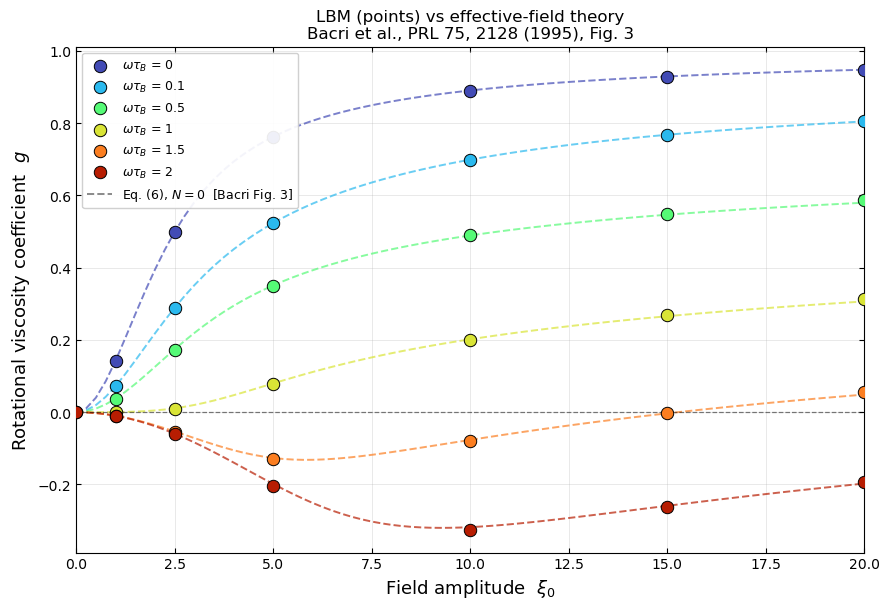

In [2]:
# =====================================================================
# CELL 2 -- read the runs, extract g, overlay on the cached curves.
#
# Requires CELL 1 to have run (THEORY in scope, or theory_cache.npz on disk).
#
#     eta = rho * S * F / (2 Q),   Q = sum_j rho_j ux_j
#     S   = sum_j (j + 1/2)(nY - 1/2 - j)          [exact discrete sum]
#     g   = (2 / (3 phi_p)) (eta - eta_0) / eta_0  [Bacri Eq. (10)]
#
# The LBM points are compared against g_demag (N = 1), NOT g_mrsh (N = 0).
# In a 2D slab with x-uniform M, B_y = -dA_z/dx = 0 identically, so
# H_y = -M_y: the solver computes the transverse demagnetising field and
# Bacri's theory does not.  Comparing against N = 0 charges the solver for
# physics it correctly includes.  `ratio_N0` is kept so the distance from
# the published Fig. 3 stays visible.
#
# eta is taken from the DC part of a harmonic fit over the CONVERGED TAIL,
# not from one snapshot.  Under an alternating field the flow settles on a
# limit cycle -- the torque carries a 2*omega component -- so a snapshot
# samples one phase of it.  Snapshot spacing rarely divides the 2w period,
# so a tail MEAN does not cancel the ripple either; the fit does not need
# commensurate sampling.  If the ripple is small (2 w t_visc >> 1) the fit
# and the last snapshot agree, and that agreement is itself the check.
# =====================================================================

import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- must match the C++ globals -------------------------------------
BASE_DIR = "output_poiseuille_experiment_alt"
phi_p  = 0.2          # PARTICLE volume fraction (the theory's phi)
eta_h  = 0.05         # field-free dynamic viscosity
rho_h  = 1.975        # heavy-phase density
tau_B  = 20.0         # Brownian time in lattice steps
UX_COL = "ux"         # "ux_avg" if the C++ writes a period average
TAIL   = 0.40         # fraction of snapshots treated as converged
NEDGE  = 1            # wall rows dropped in the shape diagnostic only

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

if "THEORY" not in globals():
    THEORY = dict(np.load("theory_cache.npz"))


def all_csvs(folder):
    out = []
    for p in glob.glob(os.path.join(folder, "output_t_*.csv")):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        if m:
            out.append((int(m.group(1)), p))
    return sorted(out)


def read_run(path, S, ux_col=UX_COL):
    df = pd.read_csv(path, skipinitialspace=True)
    col = ux_col if ux_col in df.columns else "ux"
    prof = df.groupby("j").agg(ux=(col, "mean"), rho=("rho", "mean")).sort_index()
    y, ux, rho = (prof.index.to_numpy(float), prof["ux"].to_numpy(),
                  prof["rho"].to_numpy())
    F, Q = float(df["Fb_x"].mean()), float(np.sum(rho*ux))
    eta = float(rho.mean()) * S * F / (2.0*Q) if abs(Q) > 1e-30 else np.nan
    return eta, y, ux, col


def parabola_residual(y, ux, nY):
    yi, ui = y[NEDGE:len(y)-NEDGE], ux[NEDGE:len(ux)-NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis*ui) / np.sum(basis*basis))
    return float(np.sqrt(np.mean((ui - amp*basis)**2)) /
                 max(float(np.max(np.abs(ui))), 1e-300))


def dc_from_run(folder, wtB, S, nY):
    """eta from the DC part of the converged tail; also swing and fit residual."""
    recs = all_csvs(folder)
    if not recs:
        return None
    it_all = np.array([r[0] for r in recs], float)
    cut = it_all.min() + (1.0 - TAIL)*(it_all.max() - it_all.min())
    keep = [(i, p) for i, p in recs if i >= cut] or recs[-2:]

    it, eta = [], []
    for i, p in keep:
        e, y, ux, col = read_run(p, S)
        if np.isfinite(e):
            it.append(float(i)); eta.append(e)
    if not it:
        return None
    it, eta = np.asarray(it), np.asarray(eta)

    if wtB > 1e-12 and len(eta) >= 6:
        th = 2.0*np.pi*it / (np.pi*tau_B/wtB)           # 2*omega phase
        M = np.column_stack([np.ones_like(th), np.cos(th), np.sin(th),
                             np.cos(2*th), np.sin(2*th)])
        c, *_ = np.linalg.lstsq(M, eta, rcond=None)
        eta_dc = float(c[0])
        fit_res = float(np.sqrt(np.mean((eta - M @ c)**2)) / max(abs(eta_dc), 1e-300))
    else:
        eta_dc, fit_res = float(eta.mean()), 0.0

    swing = float(eta.max() - eta.min()) / max(abs(eta_dc), 1e-300)
    _, y, ux, col = read_run(keep[-1][1], S)
    return eta_dc, swing, fit_res, y, ux, int(it[-1]), len(it), col


# ---- learn nY from the data, then read every run ---------------------
folders = [(f, FOLDER_RE.match(f)) for f in sorted(os.listdir(BASE_DIR))]
folders = [(f, m) for f, m in folders
           if m and os.path.isdir(os.path.join(BASE_DIR, f))]
if not folders:
    raise SystemExit(f"No run folders under {BASE_DIR}/")

probe = all_csvs(os.path.join(BASE_DIR, folders[0][0]))[-1][1]
nY = pd.read_csv(probe, skipinitialspace=True)["j"].nunique()
_j = np.arange(nY)
S = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))
t_visc = rho_h * nY**2 / (np.pi**2 * eta_h)

rows, used_col = [], None
for name, m in folders:
    xi0, wtB = float(m.group(1)), float(m.group(2))
    got = dc_from_run(os.path.join(BASE_DIR, name), wtB, S, nY)
    if got is None:
        print(f"  skip {name}: no usable CSV");  continue
    eta, swing, fit_res, y, ux, it, ntail, used_col = got
    if len(y) != nY:
        print(f"  skip {name}: nY={len(y)} != {nY}");  continue
    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, ntail=ntail, eta=eta,
                     swing=swing, fit_res=fit_res,
                     resid=parabola_residual(y, ux, nY), y=y, ux=ux))

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)
print(f"{len(res)} run(s) in {BASE_DIR}/   [column: {used_col}]")
print(f"nY = {nY}   S = {S:.4f}   t_visc = {t_visc:.0f} steps "
      f"(run = {res.iter.max()/t_visc:.1f} t_visc)")
print(f"eta from DC of the last {TAIL:.0%} of snapshots "
      f"({res.ntail.min()}-{res.ntail.max()} per run)")

zero = res[np.isclose(res.xi0, 0.0)]
eta0 = float(zero.eta.mean()) if len(zero) else eta_h
src = "xi0=0 run" if len(zero) else "eta_h fallback"
print(f"eta_0 = {eta0:.8f}  ({src}, nominal {eta_h:.6f}, "
      f"{100*(eta0/eta_h-1):+.3f}%)\n")
if abs(eta0/eta_h - 1) > 0.02:
    print("  WARNING: eta_0 >2% off nominal -- zero-field run not converged.\n")

res["g"] = (2.0/(3.0*phi_p)) * (res.eta - eta0) / eta0

# ---- theory at the data points, straight from the cache -------------
grid = THEORY["grid"]
res["g_N0"] = [np.interp(x, grid, THEORY[f"mrsh_{w:g}"])  for x, w in zip(res.xi0, res.wtB)]
res["g_N1"] = [np.interp(x, grid, THEORY[f"demag_{w:g}"]) for x, w in zip(res.xi0, res.wtB)]
res["dev"]      = res.g - res.g_N1                     # vs the physics solved
res["ratio"]    = np.where(np.abs(res.g_N1) > 1e-12, res.g/res.g_N1, np.nan)
res["ratio_N0"] = np.where(np.abs(res.g_N0) > 1e-12, res.g/res.g_N0, np.nan)
res["MsH0"]     = float(THEORY["r_coef"]) * res.xi0

with pd.option_context("display.width", 220, "display.max_columns", 20):
    print(res[["xi0","wtB","MsH0","eta","g","g_N1","dev","ratio",
               "g_N0","ratio_N0","swing","resid"]]
          .to_string(index=False,
                     formatters={"MsH0":"{:.4f}".format, "eta":"{:.8f}".format,
                                 "g":"{:+.4f}".format, "g_N1":"{:+.4f}".format,
                                 "dev":"{:+.4f}".format, "ratio":"{:.3f}".format,
                                 "g_N0":"{:+.4f}".format, "ratio_N0":"{:.3f}".format,
                                 "swing":"{:.2e}".format, "resid":"{:.2e}".format}))

print(f"\nvs Eq.(6) WITH N=1 demagnetisation -- the physics the solver contains:")
print(f"   max |dev| = {res.dev.abs().max():.4f}"
      f"   RMS {np.sqrt((res.dev**2).mean()):.4f}")
gapN = (res.g_N1 - res.g_N0).abs().max()
print(f"   |N=1 - N=0| = {gapN:.4f}  <- distance from Bacri's Fig. 3; "
      f"falls as 1/(tau_B H0^2)")
for w in sorted(res.wtB.unique()):
    s = res[res.wtB == w]
    print(f"   omega*tau_B = {w:<5g} max |dev| = {s.dev.abs().max():.4f}")
for _, r in res[res.fit_res > 5e-3].iterrows():
    print(f"   WARNING xi0={r.xi0:g}, wtB={r.wtB:g}: fit_res={r.fit_res:.1e} "
          f"-- tail too short for a clean DC extraction")

# ---- plot ------------------------------------------------------------
wtBs = sorted(res.wtB.unique())
colors = plt.cm.turbo(np.linspace(0.08, 0.92, max(1, len(wtBs))))
fig, ax = plt.subplots(figsize=(9, 6.2))
for c, w in zip(colors, wtBs):
    # ax.plot(grid, THEORY[f"demag_{w:g}"], color=c, lw=2.0, ls="-",  zorder=2)
    ax.plot(grid, THEORY[f"mrsh_{w:g}"],  color=c, lw=1.4, ls="--", zorder=2, alpha=0.7)
    sub = res[res.wtB == w].sort_values("xi0")
    ax.scatter(sub.xi0, sub.g, s=80, color=c, edgecolors="k", linewidths=0.7,
               zorder=3, label=rf"$\omega\tau_B$ = {w:g}")
# ax.plot([], [], color="0.35", lw=2.0, ls="-",
#         label=r"Eq. (6) + demagnetisation ($N{=}1$ slab)")
ax.plot([], [], color="0.35", lw=1.4, ls="--", alpha=0.7,
        label=r"Eq. (6), $N{=}0$  [Bacri Fig. 3]")
ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlim(0, grid.max())
ax.set_xlabel(r"Field amplitude  $\xi_0$", fontsize=13)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=13)
ax.set_title("LBM (points) vs effective-field theory\n"
             "Bacri et al., PRL 75, 2128 (1995), Fig. 3", fontsize=12)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, loc="best", framealpha=0.92)
fig.tight_layout()
plt.savefig("bacri_fig3_lbm.png", dpi=150)
plt.show()

# fig, ax = plt.subplots(figsize=(9, 4.0))
# for c, w in zip(colors, wtBs):
#     sub = res[res.wtB == w].sort_values("xi0")
#     ax.plot(sub.xi0, sub.dev, "o-", color=c, ms=7, lw=1.2,
#             markeredgecolor="k", markeredgewidth=0.6,
#             label=rf"$\omega\tau_B$ = {w:g}")
# ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
# ax.set_xlabel(r"$\xi_0$", fontsize=12)
# ax.set_ylabel(r"$g_{\rm LBM} - g_{N=1}$", fontsize=12)
# ax.set_title("Deviation from Eq. (6) with the demagnetising field included",
#              fontsize=12)
# ax.tick_params(direction="in", top=True, right=True)
# ax.grid(True, lw=0.4, alpha=0.5)
# ax.legend(fontsize=9, ncol=2)
# fig.tight_layout()
# plt.savefig("bacri_fig3_residual.png", dpi=150)
# plt.show()